# Latent TTA mit Score-Predictor — Stand 20.10.

**Frage:** Lässt sich die Segmentierung unter Domain Shift verbessern, indem man per Gradient
Ascent auf den *vorhergesagten* Dice μ̂ des QC-Heads eine kleine affine Transformation latenter
U-Net-Features anpasst — und wie weit ist das von dem entfernt, was mit Labels möglich wäre?

### Kurzfassung

1. **Die Adaption kann viel mehr, als die μ̂-TTA herausholt.** Mit dem echten (Soft-)Dice als
   Ziel erreicht dieselbe Affine an [0, 17] **0.94 / 0.93 / 0.87** (Ausgang 0.68 / 0.64 / 0.53),
   ohne einen einzigen verschlechterten Fall. Das liegt **0.19–0.25 über dem Threshold-Oracle**
   (0.75 / 0.73 / 0.63): Die Adaption verändert die Maske strukturell, nicht nur die Schwelle.
2. **Die μ̂-TTA landet etwa beim Threshold-Oracle** (3T→1.5T 0.75 vs. 0.75) oder darunter
   (PROMISE12 0.70 vs. 0.73; 1.5T→3T 0.54 vs. 0.63). **Der Engpass ist der Qualitätsschätzer,
   nicht die Adaptionsfamilie.**
3. **μ̂ reagiert stark auf Richtungen, die ihn täuschen, und schwach auf echte Verbesserungen.**
   Unter dem Oracle-Ascent steigt der Dice um +0.26 / +0.28 / +0.35, μ̂ nur um +0.12 / +0.14 / +0.04.
   Unter dem μ̂-Ascent ist es umgekehrt.
4. **Post-norm-Attachment bringt nichts** — der Dice ist gleich oder leicht schlechter, aber
   der Head wird viel stärker getäuscht (μ̂ → 0.92–0.96, κ-Median bis ~670, 90 %-Coverage → 0–5 %).
   Plausible Ursache: Der Head liest genau die Features, die adaptiert werden (Shortcut).
5. **Die Logit-Affine bringt nichts** (|Δ Dice| ≤ 0.006, auch im Oracle). Die gelernte
   Schwellenverschiebung bleibt bei −0.1 … −0.55, das Oracle läge bei −3.4 … −4.4.
6. **Gewinne und Schäden treffen verschiedene Fälle.** Verbessert werden schwache/mittlere Fälle
   (Median-Ausgangs-Dice 0.45–0.66), verschlechtert werden auf 3T→1.5T und PROMISE12 eher die
   guten (0.72–0.84). Auf 1.5T→3T bleibt die Masse (≈ 90 %) unverändert, darunter viele
   Totalausfälle, die nur das Oracle repariert.

## 0 · Aufbau

Alle Runs: PMRI, 3 Shifts (Test-Domäne), U-Net fest, **5 Score-Predictoren** (cleanHalf_0–4),
**100 Ascent-Schritte**, Adam lr 0.01, adaptiert wird eine kanalweise Affine
γ·z + β auf dem *Output* der InstanceNorm an den Swivels **[0, 17]**.

| Konfiguration | Head liest Features … | Ziel des Ascents | zusätzlich Affine auf Logits |
|---|---|---|---|
| **pre-norm** | am *Input* der InstanceNorm (Paper-Setup) | μ̂ | – |
| **pre-norm + Logits** | 〃 | μ̂ | ✓ |
| **post-norm** | am *Output* der InstanceNorm (neu) | μ̂ | – |
| **post-norm + Logits** | 〃 | μ̂ | ✓ |
| **Soft-Dice-Oracle** | (pre-norm, nur mitgeloggt) | echter Soft-Dice gegen GT | – |
| **Soft-Dice-Oracle + Logits** | 〃 | echter Soft-Dice gegen GT | ✓ |
| **Threshold-Oracle** | – | pro Bild beste Logit-Schwelle t ∈ [−16, 16] für den echten Dice, keine Adaption | – |

Beide Oracles brauchen Labels und sind **obere Schranken**, keine Methoden. Das Threshold-Oracle
beantwortet: *Wie viel wäre allein durch Verschieben der finalen Schwelle drin?* Das
Soft-Dice-Oracle: *Wie viel kann diese Adaptionsfamilie überhaupt, mit perfektem Qualitätsschätzer?*

Kennzahlen sind, wenn nicht anders angegeben, Mittelwerte über die Fälle der Testdomäne,
dann Mittel ± Std über die 5 Predictoren. Alle Konfigurationen sehen exakt dieselben Fälle
(gleiches U-Net, gleiche Reihenfolge — geprüft).

In [1]:
import glob, os, pickle, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = os.path.abspath("../../../..")  # repo root
sys.path.insert(0, f"{ROOT}/src")
from model.calibration import beta_credible_interval
from apps.plot_latent_tta import _overlay, _crop_box

DOMAINS = {
    "threet-to-onepointfivet": "3T → 1.5T",
    "promise12": "PROMISE12",
    "onepointfivet-to-threet": "1.5T → 3T",
}
PREDICTORS = range(5)
# name -> (results folder, family, logit affine)
VARIANTS = {
    "pre-norm":                  ("latent_tta_prenorm",        "pre",    False),
    "pre-norm + Logits":         ("latent_tta_prenorm_logits", "pre",    True),
    "post-norm":                 ("latent_tta_postnorm",       "post",   False),
    "post-norm + Logits":        ("latent_tta_postnorm_logits","post",   True),
    "Soft-Dice-Oracle":          ("latent_tta_oracle",         "oracle", False),
    "Soft-Dice-Oracle + Logits": ("latent_tta_oracle_logits",  "oracle", True),
}
MU_VARIANTS = [v for v in VARIANTS if VARIANTS[v][1] != "oracle"]

# colour = predictor family (fixed order), line style = logit affine
FAMILY_COLOUR = {"pre": "#2a78d6", "post": "#eb6834", "oracle": "#1baf7a"}
FAMILY_LABEL = {"pre": "μ̂-TTA, pre-norm-Head", "post": "μ̂-TTA, post-norm-Head",
                "oracle": "Soft-Dice-Oracle"}
LOGIT_STYLE = {False: "-", True: ":"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
THR_COLOUR = INK2
BASE_BINS = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.01)]
BASE_LABEL = ["< 0.25", "0.25–0.50", "0.50–0.75", "≥ 0.75"]
BASE_COLOUR = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # sequential blue, light -> dark
GROUP_COLOUR = {"verbessert": "#2a78d6", "unverändert": MUTED, "verschlechtert": "#e34948"}
TOL = 0.05   # Dice-Änderung, ab der ein Fall als verbessert / verschlechtert zählt

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

In [2]:
LEVELS = (0.5, 0.8, 0.9, 0.95)


def load(folder, domain, p):
    paths = glob.glob(f"{ROOT}/results/{folder}/pmri_{domain}_*cleanHalf_{p}_*/latent_tta.pkl")
    assert len(paths) == 1, (folder, domain, p, paths)
    with open(paths[0], "rb") as f:
        ev = pickle.load(f)["evaluation"][f"{domain}_test"]
    num = lambda t: t.float().numpy()
    r = {k: num(ev[k]) for k in (
        "dice_before", "dice_after", "mu_before", "mu_after", "kappa_before", "kappa_after",
        "best_dice", "best_step", "thr_oracle_dice", "logit_drift",
        "dice_per_step", "mu_per_step", "kappa_per_step")}
    r["thr_shift"] = num(ev["thr_oracle_shift"])[:, 0]
    if ev.get("logit_beta") is not None:
        r["logit_beta"] = num(ev["logit_beta"])[:, 0]
        r["logit_gamma"] = np.exp(num(ev["logit_log_gamma"])[:, 0])
    for when in ("before", "after"):
        r[f"bounds_{when}"] = {lvl: {k: np.asarray(ev[f"bounds_{when}"]["levels"][lvl][k])
                                     for k in ("lo", "hi", "inside")} for lvl in LEVELS}
    r["examples"] = {k: v.float().numpy() for k, v in ev["examples"].items()}
    return r


R = {(v, d, p): load(folder, d, p)
     for v, (folder, _, _) in VARIANTS.items() for d in DOMAINS for p in PREDICTORS}

# sanity: every configuration evaluates the same cases in the same order
for d in DOMAINS:
    ref = R["pre-norm", d, 0]["dice_before"]
    assert all(np.allclose(R[v, d, p]["dice_before"], ref, atol=1e-4) for v in VARIANTS for p in PREDICTORS)
print(f"{len(R)} Runs geladen;",
      ", ".join(f"{DOMAINS[d]}: {len(R['pre-norm', d, 0]['dice_before'])} Fälle" for d in DOMAINS))


def over_predictors(v, d, fn):
    vals = np.array([fn(R[v, d, p]) for p in PREDICTORS])
    return vals.mean(), vals.std()


def pm(m, s):
    return f"{m:.3f} ± {s:.3f}"


def kappa_axis(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda y, _: f"{y:g}"))
    ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())

90 Runs geladen; 3T → 1.5T: 481 Fälle, PROMISE12: 1248 Fälle, 1.5T → 3T: 1121 Fälle


## 1 · Gesamtergebnis: μ̂-TTA vs. Threshold-Oracle vs. Soft-Dice-Oracle

Mittlerer Dice auf der Testdomäne nach 100 Schritten. *Bester Schritt* = pro Bild der beste
Dice entlang der Trajektorie (braucht Labels, zeigt was ein perfekter Stopp brächte).

In [3]:
rows = []
for d, dl in DOMAINS.items():
    rows.append({"Domäne": dl, "Konfiguration": "Ausgang (keine Adaption)",
                 "Dice": pm(*over_predictors("pre-norm", d, lambda r: r["dice_before"].mean())), "bester Schritt": ""})
    rows.append({"Domäne": dl, "Konfiguration": "Threshold-Oracle (pro Bild)",
                 "Dice": pm(*over_predictors("pre-norm", d, lambda r: r["thr_oracle_dice"].mean())), "bester Schritt": ""})
    for v in VARIANTS:
        rows.append({"Domäne": dl, "Konfiguration": v,
                     "Dice": pm(*over_predictors(v, d, lambda r: r["dice_after"].mean())),
                     "bester Schritt": pm(*over_predictors(v, d, lambda r: r["best_dice"].mean()))})
summary = pd.DataFrame(rows).set_index(["Konfiguration", "Domäne"])
display(summary.unstack("Domäne").reindex([r["Konfiguration"] for r in rows[:8]])
        .reindex(columns=list(DOMAINS.values()), level=1))

Dice                                \
Domäne                           3T → 1.5T      PROMISE12      1.5T → 3T   
Konfiguration                                                              
Ausgang (keine Adaption)     0.677 ± 0.000  0.642 ± 0.000  0.526 ± 0.000   
Threshold-Oracle (pro Bild)  0.751 ± 0.000  0.725 ± 0.000  0.625 ± 0.000   
pre-norm                     0.753 ± 0.004  0.702 ± 0.011  0.538 ± 0.001   
pre-norm + Logits            0.749 ± 0.002  0.702 ± 0.012  0.540 ± 0.001   
post-norm                    0.736 ± 0.015  0.697 ± 0.007  0.532 ± 0.003   
post-norm + Logits           0.736 ± 0.015  0.698 ± 0.006  0.531 ± 0.004   
Soft-Dice-Oracle             0.937 ± 0.000  0.926 ± 0.000  0.874 ± 0.000   
Soft-Dice-Oracle + Logits    0.940 ± 0.000  0.929 ± 0.000  0.880 ± 0.000   

                            bester Schritt                                
Domäne                           3T → 1.5T      PROMISE12      1.5T → 3T  
Konfiguration                                                             
Ausgang (keine Adaption)                                                  
Threshold-Oracle (pro Bild)                                               
pre-norm                     0.783 ± 0.006  0.717 ± 0.017  0.546 ± 0.001  
pre-norm + Logits            0.783 ± 0.006  0.718 ± 0.017  0.547 ± 0.001  
post-norm                    0.743 ± 0.014  0.705 ± 0.007  0.538 ± 0.003  
post-norm + Logits           0.744 ± 0.014  0.706 ± 0.007  0.538 ± 0.004  
Soft-Dice-Oracle             0.938 ± 0.000  0.926 ± 0.000  0.874 ± 0.000  
Soft-Dice-Oracle + Logits    0.940 ± 0.000  0.929 ± 0.000  0.880 ± 0.000

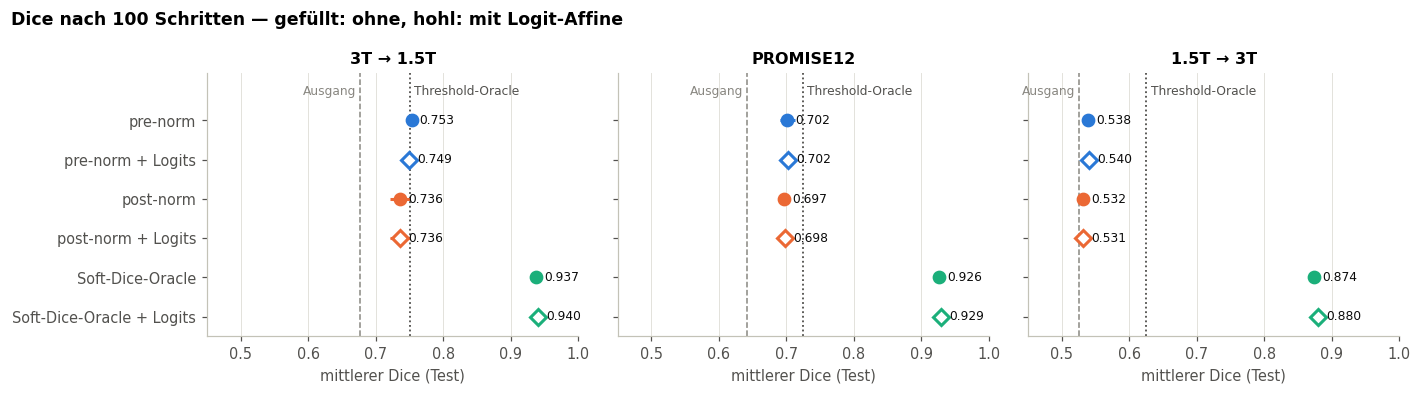

In [4]:
order = ["Ausgang", "Threshold-Oracle"] + list(VARIANTS)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    base = over_predictors("pre-norm", d, lambda r: r["dice_before"].mean())[0]
    thr = over_predictors("pre-norm", d, lambda r: r["thr_oracle_dice"].mean())[0]
    ax.axvline(base, color=MUTED, lw=1, ls="--")
    ax.axvline(thr, color=THR_COLOUR, lw=1.2, ls=(0, (1, 1.5)))
    ax.text(base - 0.006, -0.75, "Ausgang", color=MUTED, ha="right", va="center", fontsize=8)
    ax.text(thr + 0.006, -0.75, "Threshold-Oracle", color=THR_COLOUR, ha="left", va="center", fontsize=8)
    for i, v in enumerate(VARIANTS):
        _, fam, logit = VARIANTS[v]
        m, s = over_predictors(v, d, lambda r: r["dice_after"].mean())
        ax.errorbar(m, i, xerr=s, fmt="o" if not logit else "D", ms=7, color=FAMILY_COLOUR[fam],
                    mfc=FAMILY_COLOUR[fam] if not logit else "white", mew=2, capsize=0)
        ax.text(m + 0.012, i, f"{m:.3f}", va="center", fontsize=8, color=INK)
    ax.set_title(dl); ax.set_xlim(0.45, 1.0); ax.set_xlabel("mittlerer Dice (Test)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(VARIANTS)), list(VARIANTS)); axes[0].set_ylim(len(VARIANTS) - 0.5, -1.2)
fig.suptitle("Dice nach 100 Schritten — gefüllt: ohne, hohl: mit Logit-Affine", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(); plt.show()

**Befund.** Die beiden Oracles bilden einen Korridor: Threshold-Oracle ≈ was eine reine
Schwellenverschiebung kann, Soft-Dice-Oracle ≈ was die latente Affine kann. Die μ̂-TTA erreicht
höchstens die untere Kante. Auch ein perfekter Stopp (*bester Schritt*) hebt die μ̂-TTA nur um
höchstens 0.03. Zwischen den 5 Predictoren streut die μ̂-TTA wenig (Std ≤ 0.015); das Oracle ist
erwartungsgemäß identisch, weil es den Predictor nicht nutzt.

## 2 · Wo der Head die Features abgreift: pre-norm vs. post-norm

Gleiche Adaption (Affine auf dem Norm-*Output* an [0, 17]), nur der QC-Head liest an
unterschiedlicher Stelle. Spalten:

* **μ̂ vor → nach**, **Dice vor → nach** — vorhergesagte vs. echte Qualität,
* **Überschätzung** = μ̂ − Dice nach der TTA,
* **κ (Median) nach** — Konzentration der Beta-Vorhersage (vorher ≈ 12–18 in allen Konfigurationen),
* **Logit-Drift** = mittleres |Logits − Logits₀|: wie stark sich der U-Net-Output tatsächlich bewegt hat,
* **ρ(Δμ̂, ΔDice)** — Pearson pro Fall: führt ein μ̂-Gewinn auch zu einem Dice-Gewinn?

In [5]:
def head_table(variants):
    rows = []
    for d, dl in DOMAINS.items():
        for v in variants:
            f = lambda fn: over_predictors(v, d, fn)[0]
            rows.append({
                "Domäne": dl, "Konfiguration": v,
                "μ̂ vor": f(lambda r: r["mu_before"].mean()), "μ̂ nach": f(lambda r: r["mu_after"].mean()),
                "Dice vor": f(lambda r: r["dice_before"].mean()), "Dice nach": f(lambda r: r["dice_after"].mean()),
                "Überschätzung": f(lambda r: (r["mu_after"] - r["dice_after"]).mean()),
                "κ (Median) nach": f(lambda r: np.median(r["kappa_after"])),
                "Logit-Drift": f(lambda r: r["logit_drift"].mean()),
                "ρ(Δμ̂, ΔDice)": f(lambda r: np.corrcoef(r["mu_after"] - r["mu_before"],
                                                         r["dice_after"] - r["dice_before"])[0, 1]),
            })
    return pd.DataFrame(rows).set_index(["Domäne", "Konfiguration"])


head = head_table(["pre-norm", "post-norm", "Soft-Dice-Oracle"])
display(head.style.format(precision=3).format("{:.0f}", subset=["κ (Median) nach"]))

**Befund.**
* **Echter Dice:** pre-norm ist auf allen drei Domänen gleich gut oder besser (+0.017 / +0.005 / +0.006).
* **Täuschung:** Der post-norm-Head treibt μ̂ auf 0.92–0.96, die Überschätzung nach der TTA
  verdoppelt sich etwa (0.22–0.43 vs. 0.09–0.33), κ steigt auf das 2–11-Fache.
* **Mechanismus:** Der Logit-Drift ist beim post-norm-Head 2–3× *kleiner*. μ̂ steigt also, ohne dass
  sich der U-Net-Output entsprechend bewegt. Beim post-norm-Head liest der QC-Head an [0, 17]
  genau die adaptierten Features und kann direkt „überzeugt“ werden; der pre-norm-Head sieht die
  Affine nur indirekt über die nachfolgenden Layer. *Hypothese, noch nicht per Kontrollexperiment
  (Adaption und Lesepunkt getrennt) bestätigt.*
* Schon **vor** der TTA überschätzt der post-norm-Head auf 1.5T→3T stärker (μ̂ 0.80 vs. 0.73 bei Dice 0.53).
* Unter dem **Oracle** (letzte Zeile je Domäne) ist es umgekehrt: Der Dice steigt stark, μ̂ zieht
  kaum mit, die „Überschätzung“ wird negativ. Auf 1.5T→3T ist der Head für echte
  Verbesserungen fast blind (ρ = 0.15).

## 3 · Zusätzliche Affine auf den Logits

Für ein 1-Kanal-Netz ist eine Affine γ·z + β auf den Logits auf der harten Maske genau eine
**Schwellenverschiebung** t = −β/γ. Damit ist sie direkt mit dem Threshold-Oracle vergleichbar.

* **Δ Dice** = Dice(mit Logits) − Dice(ohne), gepaart pro Fall,
* **gelernte Schwelle** = mittleres −β/γ nach der TTA, **Oracle-Schwelle** = mittlere pro-Bild-optimale Schwelle.

In [6]:
rows = []
for d, dl in DOMAINS.items():
    for fam, (a, b) in {"pre-norm": ("pre-norm + Logits", "pre-norm"),
                        "post-norm": ("post-norm + Logits", "post-norm"),
                        "Soft-Dice-Oracle": ("Soft-Dice-Oracle + Logits", "Soft-Dice-Oracle")}.items():
        diff = np.concatenate([R[a, d, p]["dice_after"] - R[b, d, p]["dice_after"] for p in PREDICTORS])
        t = np.concatenate([-R[a, d, p]["logit_beta"] / R[a, d, p]["logit_gamma"] for p in PREDICTORS])
        rows.append({"Domäne": dl, "Familie": fam, "Δ Dice (Mittel)": diff.mean(),
                     f"Fälle > +{TOL}": (diff > TOL).mean(), f"Fälle < −{TOL}": (diff < -TOL).mean(),
                     "gelernte Schwelle −β/γ": t.mean(),
                     "Oracle-Schwelle": R[b, d, 0]["thr_shift"].mean()})
display(pd.DataFrame(rows).set_index(["Domäne", "Familie"]).style.format(precision=3)
        .format("{:.1%}", subset=[f"Fälle > +{TOL}", f"Fälle < −{TOL}"]))

**Befund.** Die Logit-Affine ändert den mittleren Dice um höchstens 0.006, auch wenn mit dem
echten Dice optimiert wird. Pro Fall gleichen sich kleine Gewinne und Verluste aus. Die durch μ̂
gelernte Schwelle bewegt sich kaum (−0.1 … −0.55), während das Threshold-Oracle im Mittel
−3.4 … −4.4 wählt (mehr Vordergrund). μ̂ liefert also keinen Gradienten, der die Schwelle in die
richtige Richtung zieht, und die latente Affine macht die Schwellenverschiebung im Oracle ohnehin
überflüssig. **→ Logit-Affine nicht weiterverfolgen.**

## 4 · Predicted vs. actual Dice über die Iterationen

Mittel über alle Fälle und 5 Predictoren. **Durchgezogen = echter Dice, gestrichelt = μ̂.**
Die gepunktete graue Linie ist das Threshold-Oracle. Unten: Median von κ (log-Skala).
Gezeigt ohne Logit-Affine; mit Logits sind die Kurven praktisch deckungsgleich (Abschnitt 3).

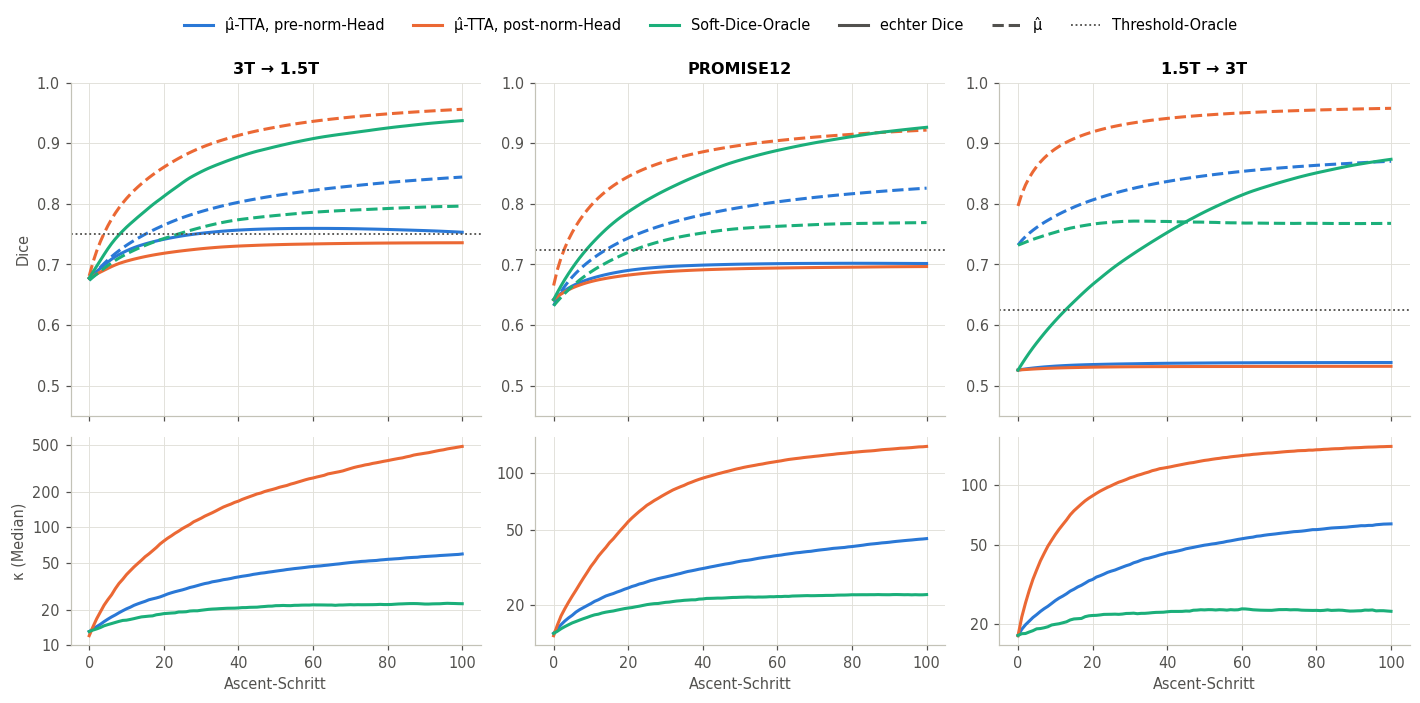

In [7]:
def mean_curve(v, d, key, agg=np.nanmean):
    return agg(np.concatenate([R[v, d, p][key] for p in PREDICTORS]), axis=0)


TRAJ = ["pre-norm", "post-norm", "Soft-Dice-Oracle"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for j, (d, dl) in enumerate(DOMAINS.items()):
    ax, axk = axes[0, j], axes[1, j]
    steps = np.arange(R["pre-norm", d, 0]["dice_per_step"].shape[1])
    for v in TRAJ:
        c = FAMILY_COLOUR[VARIANTS[v][1]]
        dice, mu = mean_curve(v, d, "dice_per_step"), mean_curve(v, d, "mu_per_step")
        ax.plot(steps, dice, color=c)
        ax.plot(steps, mu, color=c, ls="--")
        axk.plot(steps, mean_curve(v, d, "kappa_per_step", np.nanmedian), color=c)
    thr = over_predictors("pre-norm", d, lambda r: r["thr_oracle_dice"].mean())[0]
    ax.axhline(thr, color=THR_COLOUR, lw=1.2, ls=(0, (1, 1.5)))
    ax.set_title(dl); ax.set_ylim(0.45, 1.0); kappa_axis(axk)
    axk.set_xlabel("Ascent-Schritt")
axes[0, 0].set_ylabel("Dice"); axes[1, 0].set_ylabel("κ (Median)")
handles = [Line2D([], [], color=FAMILY_COLOUR[VARIANTS[v][1]], label=FAMILY_LABEL[VARIANTS[v][1]]) for v in TRAJ]
handles += [Line2D([], [], color=INK2, label="echter Dice"), Line2D([], [], color=INK2, ls="--", label="μ̂"),
            Line2D([], [], color=THR_COLOUR, lw=1.2, ls=(0, (1, 1.5)), label="Threshold-Oracle")]
plt.tight_layout(rect=(0, 0, 1, 0.94))
fig.legend(handles=handles, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.0))
plt.show()

**Befund.**
* **post-norm:** μ̂ springt in ~20 Schritten auf > 0.9 und sättigt, der echte Dice bewegt sich kaum;
  κ wächst ungebremst (log-Skala!).
* **pre-norm:** μ̂ und Dice steigen anfangs gemeinsam, ab ~Schritt 20 läuft μ̂ weiter, der Dice
  stagniert (3T→1.5T: Maximum um Schritt 50–60, danach leicht fallend).
* **Soft-Dice-Oracle:** der Dice steigt über alle 100 Schritte weiter (noch nicht gesättigt), μ̂
  bleibt bei 0.77–0.80 hängen, auf 1.5T→3T stagniert es ab Schritt ~30 komplett. κ bleibt flach
  (~22). Echte Verbesserungen machen den Head *nicht* sicherer — Täuschung schon.
* Auf 1.5T→3T bewegt die μ̂-TTA den Dice praktisch nicht (+0.01), obwohl das Oracle +0.35 schafft.

## 5 · Credible Intervals aus κ: halten sie nach der Adaption?

Aus (μ̂, κ) folgt ein Beta-Credible-Interval für den Dice. **Coverage** = Anteil der Fälle, deren
echter Dice im 90 %-Intervall liegt (Soll: 90 %). Die Fehlschläge sind aufgeteilt in
*Dice unter dem Intervall* (Head überschätzt) und *Dice über dem Intervall* (Head unterschätzt).

In [8]:
def coverage(r, when, lvl=0.9):
    b, y = r[f"bounds_{when}"][lvl], r[f"dice_{when}"]
    return b["inside"].mean(), (y < b["lo"]).mean(), (y > b["hi"]).mean()


rows = []
for d, dl in DOMAINS.items():
    for v in ["pre-norm", "post-norm", "Soft-Dice-Oracle"]:
        row = {"Domäne": dl, "Konfiguration": v}
        for when, lab in (("before", "vor"), ("after", "nach")):
            c = np.mean([coverage(R[v, d, p], when) for p in PREDICTORS], axis=0)
            row |= {f"Coverage {lab}": c[0], f"unter Intervall {lab}": c[1], f"über Intervall {lab}": c[2]}
        rows.append(row)
display(pd.DataFrame(rows).set_index(["Domäne", "Konfiguration"]).style.format("{:.0%}"))

**Befund.**
* **Vor der TTA** sind die Intervalle auf 3T→1.5T und PROMISE12 brauchbar (83–86 % bei Soll 90 %),
  auf 1.5T→3T deutlich zu optimistisch (45–54 %; der Head überschätzt hier schon ohne Adaption).
* **Nach der μ̂-TTA** fallen fast alle Fehlschläge *unter* das Intervall: pre-norm 17–58 %,
  post-norm 0–5 % Coverage. Die Intervalle werden schmal (großes κ) und liegen zu hoch.
* **Nach dem Oracle** liegt der echte Dice überwiegend *über* dem Intervall (64–72 % auf 3T→1.5T /
  PROMISE12): der Head erkennt echte Verbesserung nicht.
* κ ist damit als Vertrauenssignal *während* der Adaption unbrauchbar: Es steigt gerade dann, wenn
  der Head getäuscht wird.

## 6 · Einzelbeispiele

Pro Domäne zwei der sechs mitgespeicherten Bilder (die Snapshots sind gleichmäßig über die
Domäne verteilt, *nicht* handverlesen; daraus automatisch gewählt): **(a)** das Bild, auf dem die
μ̂-TTA (pre-norm) am meisten gewinnt, **(b)** das Bild, auf dem der post-norm-Head am stärksten
überschätzt. Predictor cleanHalf_0.

Oben je Konfiguration: echter Dice (durchgezogen), μ̂ (gestrichelt) mit 90 %-Credible-Band,
Threshold-Oracle (gepunktet); rechts κ. Unten die Masken:
**grün = richtig, rot = falsch positiv, blau = falsch negativ.**

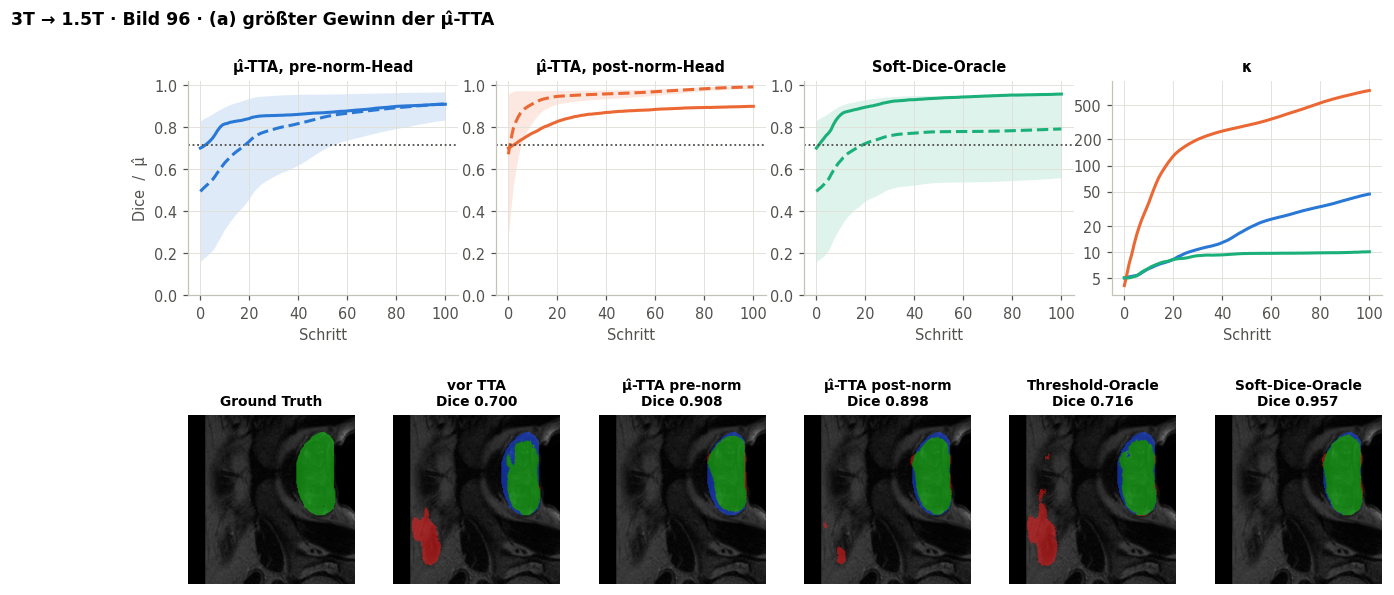

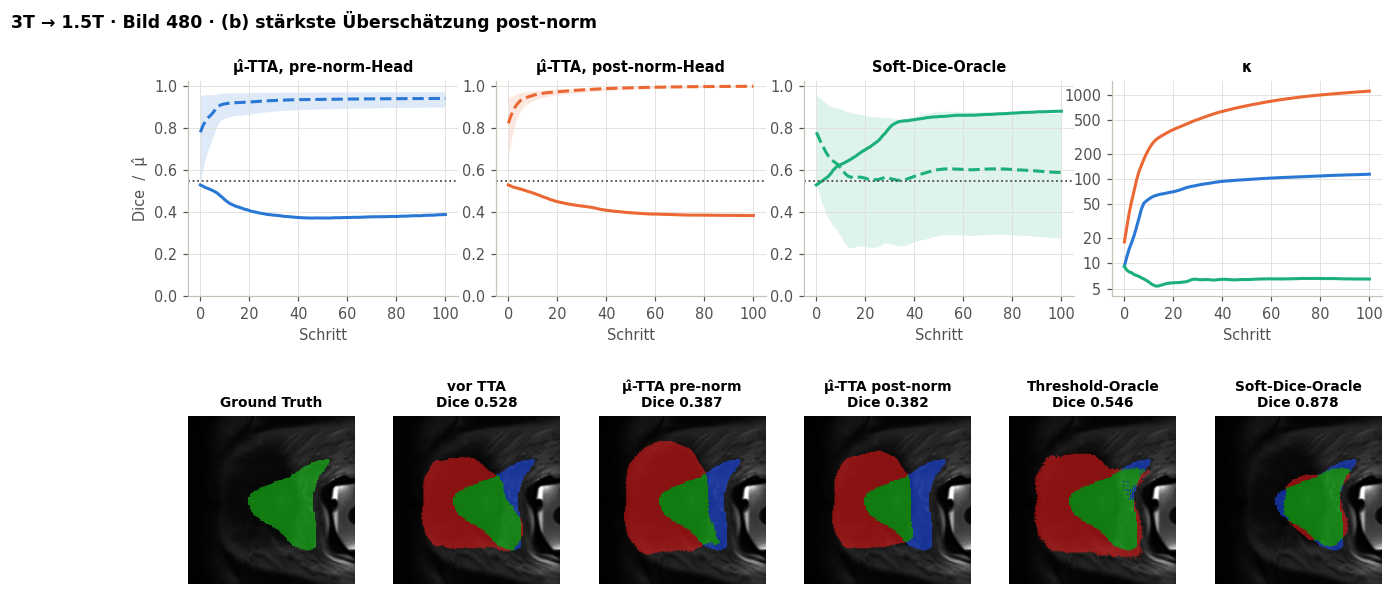

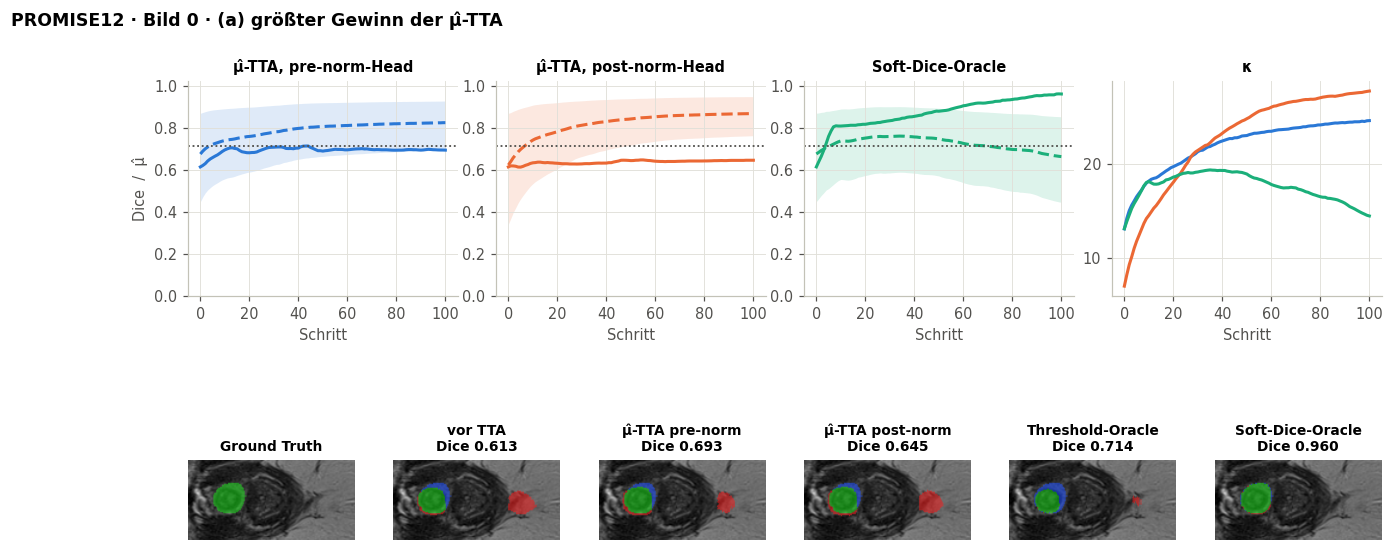

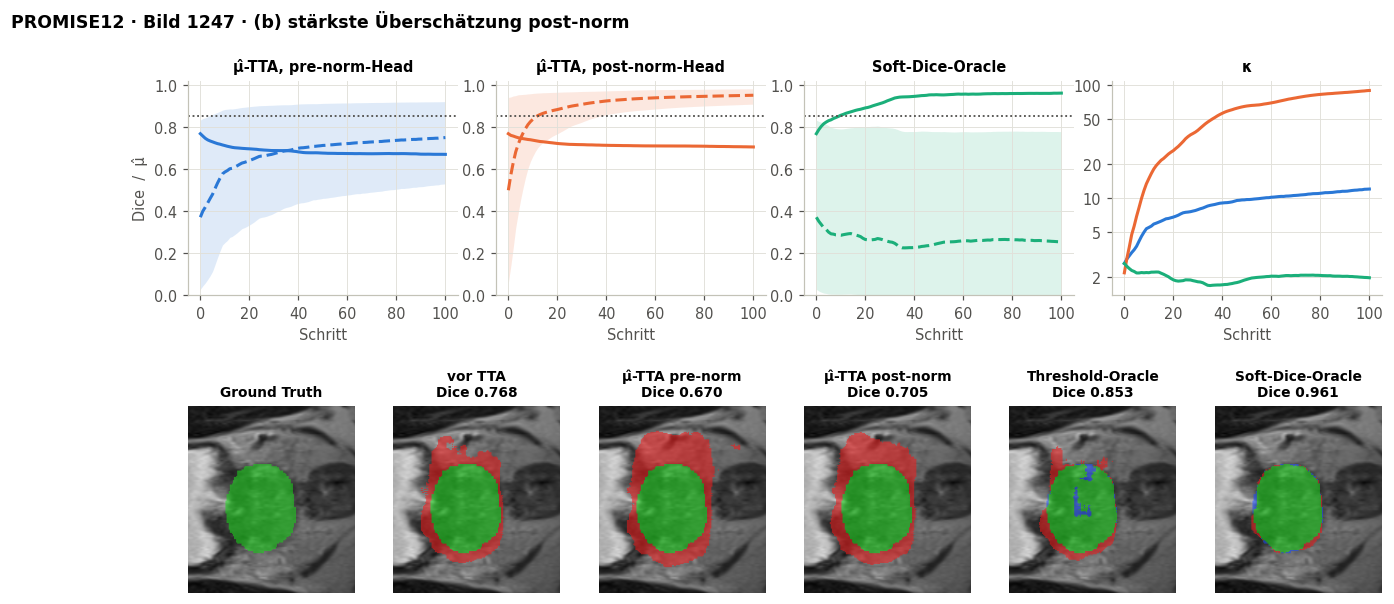

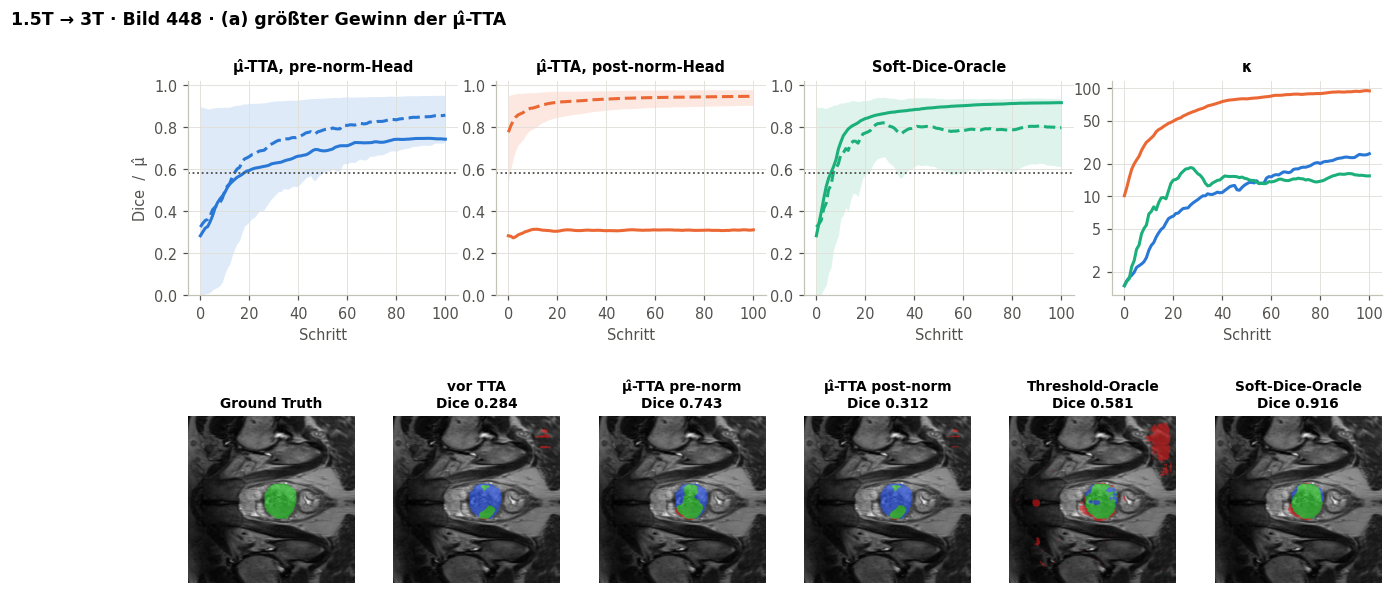

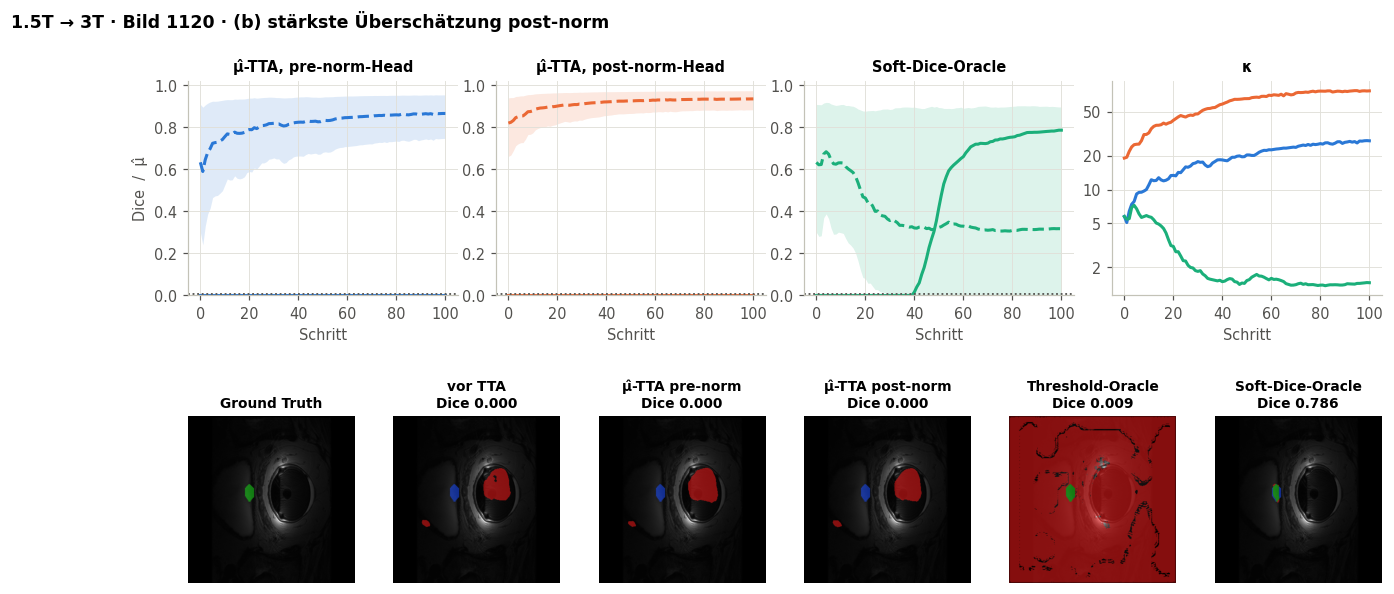

In [9]:
def pick_examples(d, p=0):
    ex_idx = R["pre-norm", d, p]["examples"]["index"].astype(int)
    pre, post = R["pre-norm", d, p], R["post-norm", d, p]
    gain = pre["dice_after"][ex_idx] - pre["dice_before"][ex_idx]
    over = post["mu_after"][ex_idx] - post["dice_after"][ex_idx]
    a = int(np.argmax(gain))
    b = next(int(k) for k in np.argsort(-over) if k != a)
    return [(a, "(a) größter Gewinn der μ̂-TTA"), (b, "(b) stärkste Überschätzung post-norm")]


def plot_case(d, k, why, p=0):
    runs = {v: R[v, d, p] for v in TRAJ}
    i = int(runs["pre-norm"]["examples"]["index"][k])
    thr = runs["pre-norm"]["thr_oracle_dice"][i]
    fig = plt.figure(figsize=(14, 6.4))
    gs = fig.add_gridspec(2, 12, height_ratios=[1, 1.15], hspace=0.35, wspace=0.6)
    axes = [fig.add_subplot(gs[0, 3 * j:3 * j + 3]) for j in range(3)]
    axk = fig.add_subplot(gs[0, 9:12])
    for ax, (v, r) in zip(axes, runs.items()):
        c = FAMILY_COLOUR[VARIANTS[v][1]]
        dice, mu, kap = r["dice_per_step"][i], r["mu_per_step"][i], r["kappa_per_step"][i]
        lo, hi = beta_credible_interval(mu, kap, coverage=0.9)
        s = np.arange(len(dice))
        ax.fill_between(s, lo, hi, color=c, alpha=0.15, lw=0)
        ax.plot(s, dice, color=c); ax.plot(s, mu, color=c, ls="--")
        ax.axhline(thr, color=THR_COLOUR, lw=1.2, ls=(0, (1, 1.5)))
        ax.set_title(FAMILY_LABEL[VARIANTS[v][1]], fontsize=9.5); ax.set_ylim(0, 1.02)
        ax.set_xlabel("Schritt")
        axk.plot(s, kap, color=c)
    axes[0].set_ylabel("Dice  /  μ̂")
    kappa_axis(axk); axk.set_title("κ", fontsize=9.5); axk.set_xlabel("Schritt")
    ex = {v: r["examples"] for v, r in runs.items()}
    e0 = ex["pre-norm"]
    panels = [("Ground Truth", e0["target"][k], None),
              ("vor TTA", e0["pred_before"][k], runs["pre-norm"]["dice_before"][i]),
              ("μ̂-TTA pre-norm", ex["pre-norm"]["pred_final"][k], runs["pre-norm"]["dice_after"][i]),
              ("μ̂-TTA post-norm", ex["post-norm"]["pred_final"][k], runs["post-norm"]["dice_after"][i]),
              ("Threshold-Oracle", e0["pred_threshold"][k], thr),
              ("Soft-Dice-Oracle", ex["Soft-Dice-Oracle"]["pred_final"][k], runs["Soft-Dice-Oracle"]["dice_after"][i])]
    ys, xs = _crop_box([m for _, m, _ in panels], e0["target"][k].shape)
    for j, (title, m, dsc) in enumerate(panels):
        ax = fig.add_subplot(gs[1, 2 * j:2 * j + 2])
        ax.imshow(_overlay(e0["image"][k], e0["target"][k], m)[ys, xs])
        ax.set_title(title + ("" if dsc is None else f"\nDice {dsc:.3f}"), fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{DOMAINS[d]} · Bild {i} · {why}", x=0.01, ha="left", fontweight="bold")
    plt.show()


for d in DOMAINS:
    for k, why in pick_examples(d):
        plot_case(d, k, why)

**Was die Beispiele zeigen** (Masken-Farben: grün richtig, rot FP, blau FN):

* **3T→1.5T, Bild 96:** Die μ̂-TTA entfernt einen separaten FP-Fleck und füllt FN auf
  (0.70 → 0.91). Das Threshold-Oracle kann das nicht (0.72): Eine Schwelle kann nicht den Fleck
  entfernen und gleichzeitig mehr Prostata aufnehmen. → Die latente Adaption *kann* strukturell
  korrigieren.
* **3T→1.5T, Bild 480:** großer FP-Bereich. Beide μ̂-Varianten vergrößern ihn (0.53 → 0.39),
  während μ̂ auf 0.94 bzw. 1.0 steigt. Das Oracle entfernt ihn (0.88).
* **PROMISE12, Bild 1247:** Übersegmentierung. Die μ̂-TTA macht sie schlimmer (0.77 → 0.67),
  das Threshold-Oracle korrigiert teilweise (0.85), das Oracle fast vollständig (0.96) — und μ̂
  *fällt* dabei auf ~0.25.
* **1.5T→3T, Bild 448:** pre-norm-TTA 0.28 → 0.74 (über dem Threshold-Oracle 0.58); der post-norm-
  Head bleibt bei 0.31, obwohl sein μ̂ auf 0.95 steigt.
* **1.5T→3T, Bild 1120:** Totalausfall (Dice 0, Vorhersage auf falscher Struktur), μ̂ sagt
  trotzdem 0.6–0.9. Weder μ̂-TTA noch Schwelle helfen; das Oracle findet die Prostata nach
  ~40 Schritten (0.79), während μ̂ auf ~0.3 fällt.

## 7 · Verbessert / verschlechtert in Abhängigkeit vom Ausgangs-Dice

Ein Fall gilt als **verbessert**, wenn sein Dice mehr als 0.05 über dem Ausgangswert liegt,
als **verschlechtert**, wenn er mehr als 0.05 darunter liegt. Fälle × 5 Predictoren gepoolt.

### 7.1 Verlauf über die Schritte, je Bin des Ausgangs-Dice
Oben Anteil verbessert (0–100 %), unten Anteil verschlechtert (0–25 %, gestreckt); gleiche
Skalen in beiden Abbildungen. Beim Soft-Dice-Oracle
wird kein einziger Fall schlechter; es ist deshalb hier nicht gezeigt.

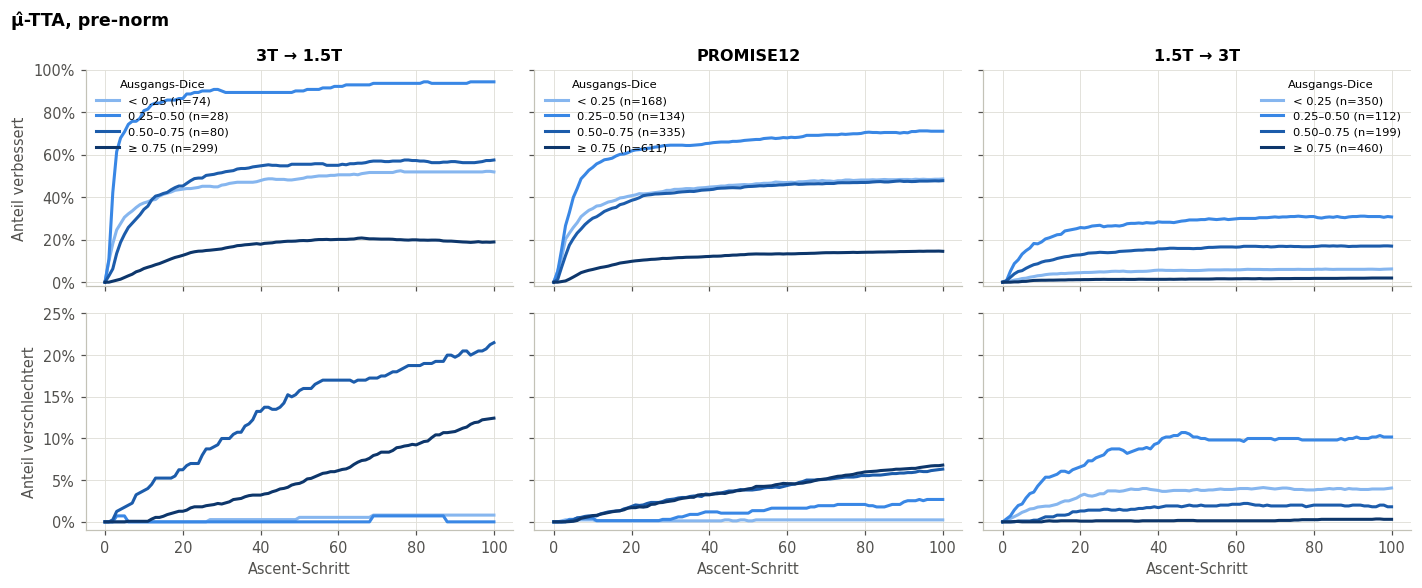

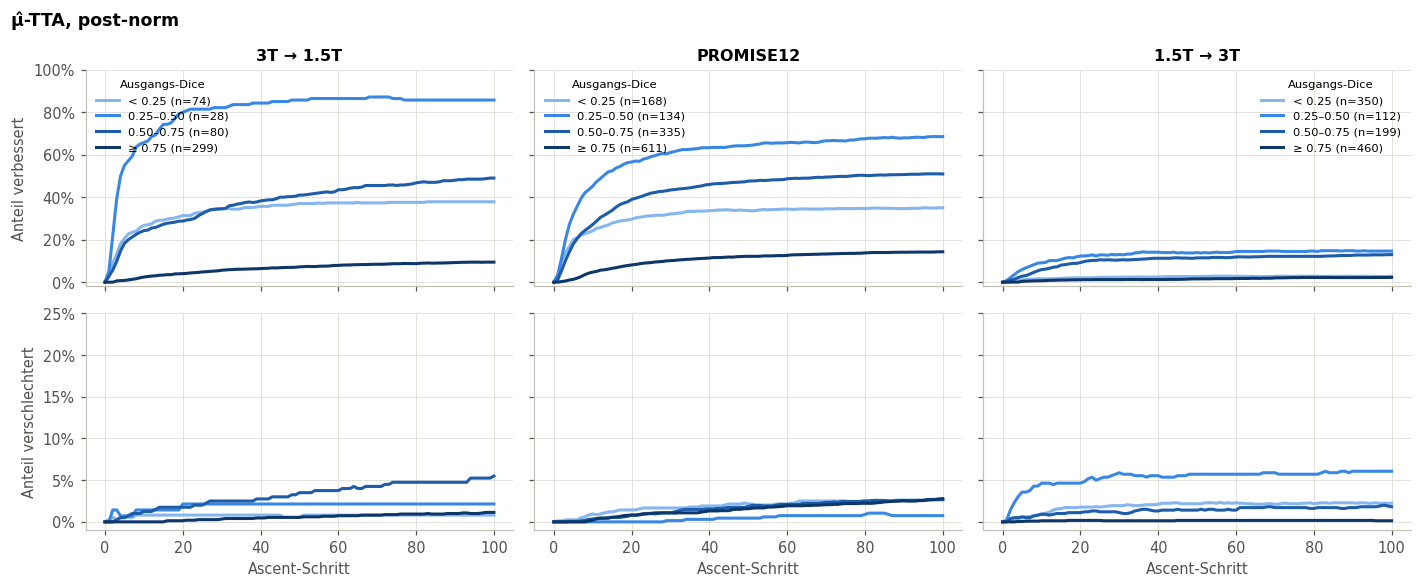

In [10]:
def bin_masks(start):
    return [(start >= lo) & (start < hi) for lo, hi in BASE_BINS]


def plot_helped_harmed(v, tol=TOL):
    fig, axes = plt.subplots(2, 3, figsize=(13, 5.4), sharex=True, sharey="row")
    for j, (d, dl) in enumerate(DOMAINS.items()):
        C = np.concatenate([R[v, d, p]["dice_per_step"] for p in PREDICTORS])
        start = C[:, :1]
        up, down = (C > start + tol), (C < start - tol)
        for m, lab, col in zip(bin_masks(start[:, 0]), BASE_LABEL, BASE_COLOUR):
            if m.sum() < 20:
                continue
            axes[0, j].plot(up[m].mean(0), color=col, label=f"{lab} (n={m.sum() // 5})")
            axes[1, j].plot(down[m].mean(0), color=col)
        axes[0, j].set_title(dl); axes[1, j].set_xlabel("Ascent-Schritt")
        axes[0, j].legend(title="Ausgangs-Dice", fontsize=7.5, title_fontsize=7.5)
        axes[0, j].set_ylim(-0.02, 1.0); axes[1, j].set_ylim(-0.01, 0.25)
        for ax in axes[:, j]:
            ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    axes[0, 0].set_ylabel("Anteil verbessert"); axes[1, 0].set_ylabel("Anteil verschlechtert")
    fig.suptitle(f"μ̂-TTA, {v}", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()


for v in ["pre-norm", "post-norm"]:
    plot_helped_harmed(v)

### 7.2 Umgekehrt: welchen Ausgangs-Dice hatten die Gruppen?

Stand nach 100 Schritten. Pro Gruppe Anteil der Fälle und Median [IQR] des Ausgangs-Dice.

In [11]:
def groups(v, d):
    before = np.concatenate([R[v, d, p]["dice_before"] for p in PREDICTORS])
    after = np.concatenate([R[v, d, p]["dice_after"] for p in PREDICTORS])
    delta = after - before
    g = np.where(delta > TOL, "verbessert", np.where(delta < -TOL, "verschlechtert", "unverändert"))
    return before, g


rows = []
for d, dl in DOMAINS.items():
    for v in ["pre-norm", "post-norm", "Soft-Dice-Oracle"]:
        before, g = groups(v, d)
        for name in GROUP_COLOUR:
            b = before[g == name]
            q = np.percentile(b, [25, 50, 75]) if len(b) else [np.nan] * 3
            rows.append({"Domäne": dl, "Konfiguration": v, "Gruppe": name, "Anteil": len(b) / len(before),
                         "Ausgangs-Dice Median": q[1], "IQR": f"[{q[0]:.2f}, {q[2]:.2f}]" if len(b) else "–"})
tab = pd.DataFrame(rows).set_index(["Domäne", "Konfiguration", "Gruppe"])
display(tab.style.format({"Anteil": "{:.0%}", "Ausgangs-Dice Median": "{:.2f}"}))

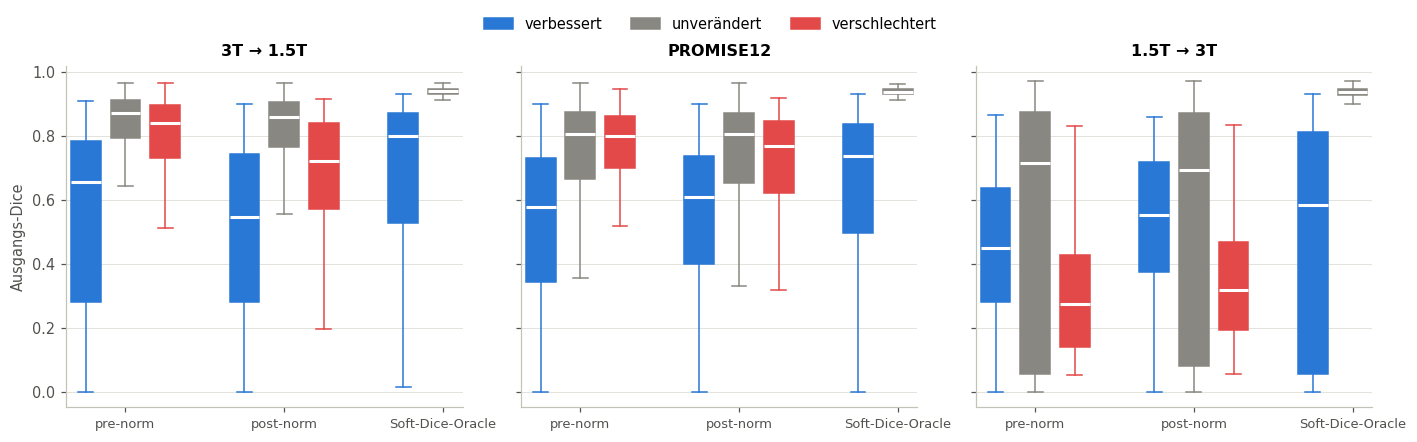

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    pos, data, cols, ticks = [], [], [], []
    for gi, v in enumerate(["pre-norm", "post-norm", "Soft-Dice-Oracle"]):
        before, g = groups(v, d)
        for k, name in enumerate(GROUP_COLOUR):
            b = before[g == name]
            if len(b) < 10:
                continue
            pos.append(gi * 4 + k); data.append(b); cols.append(GROUP_COLOUR[name])
        ticks.append((gi * 4 + 1, v))
    bp = ax.boxplot(data, positions=pos, widths=0.75, patch_artist=True, showfliers=False,
                    medianprops=dict(color="white", lw=2))
    for patch, c in zip(bp["boxes"], cols):
        patch.set(facecolor=c, edgecolor=c)
    for el in ("whiskers", "caps"):
        for line, c in zip(bp[el], np.repeat(cols, 2)):
            line.set(color=c)
    ax.set_xticks([t for t, _ in ticks], [l for _, l in ticks], fontsize=8.5)
    ax.set_title(dl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Ausgangs-Dice")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=n) for n, c in GROUP_COLOUR.items()],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

**Befund.**
* **Wer gewinnt:** vor allem Fälle mit mittlerem Ausgangs-Dice (Bin 0.25–0.50: 68–95 % verbessert
  auf 3T→1.5T / PROMISE12). Die Gewinne entstehen fast vollständig in den ersten ~20 Schritten.
* **Wer verliert:** auf 3T→1.5T und PROMISE12 eher gute Fälle (Median-Ausgangs-Dice der
  Verschlechterten 0.72–0.84). Der Anteil wächst über die Schritte stetig weiter (pre-norm,
  3T→1.5T, Bin 0.50–0.75: 21 % verschlechtert, 57 % verbessert nach 100 Schritten). → Argument für frühes Stoppen bzw. nur
  unsichere Fälle zu adaptieren.
* **post-norm** verschlechtert weniger, verbessert aber auch weniger: Er bewegt die Maske insgesamt
  weniger (vgl. Logit-Drift in Abschnitt 2).
* **1.5T→3T:** 88–93 % bleiben unverändert, auch viele Fälle mit Ausgangs-Dice < 0.25
  (IQR der Unveränderten reicht bis 0.06). Die μ̂-TTA repariert Totalausfälle nicht, das Oracle
  verbessert dagegen 90 % aller Fälle, auch diese.
* Das **Soft-Dice-Oracle** verbessert 90–96 % der Fälle; unverändert bleiben nur die, die schon
  bei ≈ 0.94 liegen. Verschlechtert: keiner.

## 8 · Fazit und nächste Schritte

**Was wir jetzt wissen**
* Die latente Affine an zwei Swivels ist ausdrucksstark genug (Oracle 0.87–0.94).
* Der limitierende Faktor ist μ̂ als Zielfunktion: Es lässt sich adversarial hochtreiben und
  reagiert kaum auf echte Verbesserungen. κ und die Credible Intervals verschlechtern sich unter
  Adaption systematisch.
* Post-norm-Attachment und Logit-Affine verbessern nichts → nicht weiterverfolgen.

**Mögliche nächste Schritte (zur Diskussion)**
1. **Kontrollexperiment Shortcut:** Adaptieren an Stellen, die der Head nicht direkt liest
   (z. B. adaptieren [0], lesen [17]). Erwartung, falls die Hypothese stimmt: höherer Logit-Drift,
   kleinere Überschätzung.
2. **Robusteren Schätzer trainieren:** den Head beim Training gegen genau diese latenten
   Affinen absichern (adversariale Augmentierung mit γ, β), sodass „Täuschungs-Richtungen“ nicht
   mehr zu höherem μ̂ führen.
3. **Schadensbegrenzung mit dem jetzigen Head:** frühes Stoppen (Gewinne liegen in den ersten
   ~20 Schritten) und selektive Adaption nur der unsichersten Fälle (Gate auf μ̂, siehe
   `results_per_case.ipynb`, Abschnitt 6), ggf. Abbruch, wenn κ stark steigt.
4. **M&Ms-Splits** sind für die TTA noch nicht gerechnet.